# CNN-LSTM Emulator for ClimateBench: Projecting Climate under SSP245

**Goal.** Train a neural-network *emulator* that turns greenhouse-gas and aerosol emissions into annual global maps of four climate variables, then use it to project a scenario it has never seen, **SSP245 (2015–2100)**, without running a full Earth System Model.

**Approach.** Each training sample is a 10-year window of emission maps. A convolutional layer extracts features from each year's maps, an LSTM summarizes how those features change over the decade, and a dense layer converts that summary into a 96 × 144 map of the target variable for the last year of the window.

| Section | What happens |
|---|---|
| 1. Data | Load ClimateBench inputs and outputs for five training simulations |
| 2. Normalization | Standardize the four emission inputs |
| 3. Training samples | Cut the records into 10-year sliding windows (726 samples) |
| 4. Model | Define the CNN-LSTM and a five-seed ensemble experiment |
| 5. Training | Train on surface temperature (`tas`) and inspect the loss |
| 6. Prediction | Predict SSP245 and map 2020, 2050 and 2100 |
| 7. Full pipeline | Repeat for `tas`, `dtr`, `pr`, `pr90` and save NetCDF files |
| 8. Summary | Results, limitations and next steps |

**Key results so far**
- The `tas` model trains stably: mean squared error falls from 2.05 K² after the first epoch to about 0.29 K² by epoch 16 and levels off there (RMSE ≈ 0.54 K, measured on the training data).
- The saved run does not yet contain SSP245 predictions, maps or the seed-ensemble spread. Those cells stopped with errors, which are explained (with fixes) in sections 4 and 6.

## Setup

Standard scientific Python stack: `xarray` reads the NetCDF climate files, and `cartopy` with `matplotlib` draws maps. `data_path` comes from the local `utils.py` and should point to the folder that holds the ClimateBench `inputs_*.nc` and `outputs_*.nc` files.

In [4]:
import numpy as np
import xarray as xr
import pandas as pd
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

from utils import data_path

# Load data

## 1. Data

The data come from **ClimateBench v1.0** (Watson-Parris et al., 2022), a benchmark built from simulations of the **NorESM2-LM** Earth System Model. Every field is annual and sits on a 96 × 144 latitude–longitude grid (about 1.9° × 2.5°).

### Simulations

| Simulation | Years | What it represents | Role here |
|---|---|---|---|
| `historical` | 1850–2014 (165 yr) | Forcing from the observed past | Prepended to each SSP |
| `ssp126` | 2015–2100 (86 yr) | Strong mitigation, low emissions | Training |
| `ssp370` | 2015–2100 | High emissions and high aerosol pollution | Training |
| `ssp585` | 2015–2100 | Very high, fossil-fuelled emissions | Training |
| `hist-GHG` | 1850–2014 | Historical period with greenhouse gases only | Training |
| `hist-aer` | 1850–2014 | Historical period with aerosols only | Training |
| `ssp245` | 2015–2100 | Middle-of-the-road, intermediate emissions | **Test (held out)** |

`hist-GHG` and `hist-aer` are single-forcing runs. They let the model separate the warming effect of greenhouse gases from the cooling effect of aerosols, which are mixed together in every other simulation.

### Variables

| Type | Variable | Description | Per-year shape | Units |
|---|---|---|---|---|
| Input | `CO2` | Cumulative anthropogenic CO₂ emissions | Global value | GtCO₂ |
| Input | `CH4` | Annual CH₄ emissions | Global value | GtCH₄ yr⁻¹ |
| Input | `SO2` | Sulfur dioxide emissions (sulfate aerosol precursor) | 96 × 144 map | kg m⁻² s⁻¹ |
| Input | `BC` | Black carbon emissions | 96 × 144 map | kg m⁻² s⁻¹ |
| Output | `tas` | Near-surface air temperature | 96 × 144 map | K |
| Output | `diurnal_temperature_range` | Daily maximum minus daily minimum temperature | 96 × 144 map | K |
| Output | `pr` | Precipitation | 96 × 144 map | mm day⁻¹ after conversion |
| Output | `pr90` | 90th percentile of daily precipitation (extremes) | 96 × 144 map | mm day⁻¹ after conversion |

Outputs are anomalies relative to the model's pre-industrial control climate, so 0 means "no change". When the inputs are stacked into one array, the global `CO2` and `CH4` values are repeated across every grid cell so all four inputs share the 96 × 144 shape.

In [3]:
simus = ['ssp126',
         'ssp370',
         'ssp585',
         'hist-GHG',
         'hist-aer']

In [4]:
len_historical = 165

### Loading procedure

For each training simulation, the next cell:

1. **Opens the inputs.** For the SSPs it joins `historical` and the SSP into one continuous 1850–2100 record (251 years).
2. **Opens the outputs and averages over ensemble members** (`.mean(dim='member')`). Averaging several runs of the same scenario cancels out much of the random year-to-year weather noise, so the model learns the *forced* climate response.
3. **Converts `pr` and `pr90` to mm day⁻¹** by multiplying by 86 400 s day⁻¹, which brings the values to order 1.
4. **Tidies the dataset:** renames `lon`/`lat` to `longitude`/`latitude`, orders dimensions as (time, latitude, longitude) and drops the unused `quantile` coordinate.

In [5]:
X_train = []
Y_train = []

for i, simu in enumerate(simus):

    input_name = 'inputs_' + simu + '.nc'
    output_name = 'outputs_' + simu + '.nc'

    # Just load hist data in these cases 'hist-GHG' and 'hist-aer'
    if 'hist' in simu:
        # load inputs 
        input_xr = xr.open_dataset(data_path + input_name)
            
        # load outputs                                                             
        output_xr = xr.open_dataset(data_path + output_name).mean(dim='member')
        output_xr = output_xr.assign({"pr": output_xr.pr * 86400,
                                      "pr90": output_xr.pr90 * 86400}).rename({'lon':'longitude', 
                                                                               'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])
    
    # Concatenate with historical data in the case of scenario 'ssp126', 'ssp370' and 'ssp585'
    else:
        # load inputs 
        input_xr = xr.open_mfdataset([data_path + 'inputs_historical.nc', 
                                    data_path + input_name]).compute()
            
        # load outputs                                                             
        output_xr = xr.concat([xr.open_dataset(data_path + 'outputs_historical.nc').mean(dim='member'),
                               xr.open_dataset(data_path + output_name).mean(dim='member')],
                               dim='time').compute()
        output_xr = output_xr.assign({"pr": output_xr.pr * 86400,
                                      "pr90": output_xr.pr90 * 86400}).rename({'lon':'longitude', 
                                                                               'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])

    print(input_xr.dims, simu)

    # Append to list 
    X_train.append(input_xr)
    Y_train.append(output_xr)

/var/folders/nm/70bqztgj6n5dks5f1tz3vwsm0000gn/T/ipykernel_91553/2940385875.py:32: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])


FrozenMappingWarningOnValuesAccess({'time': 251, 'latitude': 96, 'longitude': 144}) ssp126


/var/folders/nm/70bqztgj6n5dks5f1tz3vwsm0000gn/T/ipykernel_91553/2940385875.py:32: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])
/var/folders/nm/70bqztgj6n5dks5f1tz3vwsm0000gn/T/ipykernel_91553/2940385875.py:32: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])


FrozenMappingWarningOnValuesAccess({'time': 251, 'latitude': 96, 'longitude': 144}) ssp370
FrozenMappingWarningOnValuesAccess({'time': 251, 'latitude': 96, 'longitude': 144}) ssp585
FrozenMappingWarningOnValuesAccess({'time': 165, 'latitude': 96, 'longitude': 144}) hist-GHG
FrozenMappingWarningOnValuesAccess({'time': 165, 'latitude': 96, 'longitude': 144}) hist-aer


/var/folders/nm/70bqztgj6n5dks5f1tz3vwsm0000gn/T/ipykernel_91553/2940385875.py:18: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])
/var/folders/nm/70bqztgj6n5dks5f1tz3vwsm0000gn/T/ipykernel_91553/2940385875.py:18: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  'lat': 'latitude'}).transpose('time','latitude', 'longitude').drop(['quantile'])


**Output.** The three SSP records have 251 time steps (165 historical + 86 future) and the two single-forcing runs have 165, all on the 96 × 144 grid. The `FutureWarning` is harmless: newer xarray versions prefer `.drop_vars(['quantile'])` over `.drop(['quantile'])`.

## 2. Normalization

The four inputs differ by about 16 orders of magnitude (CO₂ is around 10³, BC around 10⁻¹³). Without rescaling, the network would effectively ignore the aerosol inputs. Each input is therefore standardized to zero mean and unit standard deviation:

$$x_{\text{norm}} = \frac{x - \mu}{\sigma}$$

**How μ and σ are computed.** The statistics are taken over the whole training set, counting the historical period only once. Because `historical` is attached to all three SSP records, the code keeps those years from `ssp126` and slices them off `ssp370` and `ssp585`; otherwise 1850–2014 would be counted three times and skew the statistics toward the past. The same μ and σ are reused later on the test scenario, so no information from SSP2-4.5 leaks into training.

Only the inputs are normalized. The outputs stay in physical units, so the model predicts K or mm day⁻¹ directly.

# Data normalization

In [6]:
# Utilities for normalizing the input data
def normalize(data, var, meanstd_dict):
    mean = meanstd_dict[var][0]
    std = meanstd_dict[var][1]
    return (data - mean)/std

def unnormalize(data, var, meanstd_dict):
    mean = meanstd_dict[var][0]
    std = meanstd_dict[var][1]
    return data * std + mean

In [7]:
# Compute mean/std of each variable for the whole dataset
meanstd_inputs = {}

for var in ['CO2', 'CH4', 'SO2', 'BC']:
    # To not take the historical data into account several time we have to slice the scenario datasets
    # and only keep the historical data once (in the first ssp index 0 in the simus list)
    array = np.concatenate([X_train[i][var].data for i in [0, 3, 4]] + 
                           [X_train[i][var].sel(time=slice(len_historical, None)).data for i in range(1, 3)])
    print((array.mean(), array.std()))
    meanstd_inputs[var] = (array.mean(), array.std())

(np.float64(1074.172303244536), np.float64(1755.690699230666))
(np.float64(0.1927369743762821), np.float64(0.18457590641432994))
(np.float64(2.562335999706673e-12), np.float64(2.2501145667832657e-11))
(np.float64(1.494790500981809e-13), np.float64(1.0313342554838398e-12))


**Output: normalization statistics**

| Input | Mean (μ) | Std (σ) |
|---|---|---|
| `CO2` | 1074.2 GtCO₂ | 1755.7 GtCO₂ |
| `CH4` | 0.193 GtCH₄ yr⁻¹ | 0.185 GtCH₄ yr⁻¹ |
| `SO2` | 2.56 × 10⁻¹² kg m⁻² s⁻¹ | 2.25 × 10⁻¹¹ kg m⁻² s⁻¹ |
| `BC` | 1.49 × 10⁻¹³ kg m⁻² s⁻¹ | 1.03 × 10⁻¹² kg m⁻² s⁻¹ |

For `SO2` and `BC` the standard deviation is 7–9 times the mean. That reflects how concentrated these emissions are: a few industrial regions emit heavily while most grid cells (oceans and remote land) are close to zero. For `CO2`, the large spread comes from cumulative emissions growing from near zero in 1850 to thousands of GtCO₂ by 2100 in the high-emission scenarios.

In [8]:
# normalize input data 
X_train_norm = [] 
for i, train_xr in enumerate(X_train): 
    for var in ['CO2', 'CH4', 'SO2', 'BC']: 
        var_dims = train_xr[var].dims
        train_xr=train_xr.assign({var: (var_dims, normalize(train_xr[var].data, var, meanstd_inputs))}) 
    X_train_norm.append(train_xr)

## 3. Building training samples: 10-year sliding windows

Climate responds to the *history* of emissions, not only to the current year (for example, the ocean absorbs heat slowly, which delays warming). So each sample shows the model a 10-year window of inputs and asks for the climate map in the **last** year of that window:

- **Input `X`:** years *t − 9 … t* of all four normalized inputs, shape `(10, 96, 144, 4)`
- **Target `Y`:** the chosen output variable in year *t*, shape `(1, 96, 144)`

The window slides forward one year at a time. `skip_historical` prevents the historical period from appearing three times: for `ssp126` and `ssp370` the first window is the one ending in 2015, so they contribute only future targets, while `ssp585` keeps its full 1850–2100 record and contributes the historical targets once. (The normalization step kept the historical copy from `ssp126` rather than `ssp585`; since the historical years are identical in all three records, the outcome is the same.)

| Simulation | Years in record | Windows used | Target years |
|---|---|---|---|
| `ssp126` | 251 | 86 | 2015–2100 |
| `ssp370` | 251 | 86 | 2015–2100 |
| `ssp585` | 251 | 242 | 1859–2100 |
| `hist-GHG` | 165 | 156 | 1859–2014 |
| `hist-aer` | 165 | 156 | 1859–2014 |
| **Total** | | **726** | |

## Reshape data to feed into the model 

In [9]:
slider = 10 # years moving temporal window 

In [10]:
# Functions for reshaping the data 
def input_for_training(X_train_xr, skip_historical=False, len_historical=None): 
    
    X_train_np =  X_train_xr.to_array().transpose('time', 'latitude', 'longitude', 'variable').data

    time_length = X_train_np.shape[0]
    # If we skip historical data, the first sequence created has as last element the first scenario data point
    if skip_historical:
        X_train_to_return = np.array([X_train_np[i:i+slider] for i in range(len_historical-slider+1, time_length-slider+1)])
    # Else we just go through the whole dataset historical + scenario (does not matter in the case of 'hist-GHG' and 'hist_aer')
    else:
        X_train_to_return = np.array([X_train_np[i:i+slider] for i in range(0, time_length-slider+1)])
    
    return X_train_to_return 


def output_for_training(Y_train_xr, var, skip_historical=False, len_historical=None): 
    Y_train_np = Y_train_xr[var].data
    
    time_length = Y_train_np.shape[0]
    
    # If we skip historical data, the first sequence created has as target element the first scenario data point
    if skip_historical:
        Y_train_to_return = np.array([[Y_train_np[i+slider-1]] for i in range(len_historical-slider+1, time_length-slider+1)])
    # Else we just go through the whole dataset historical + scenario (does not matter in the case of 'hist-GHG' and 'hist_aer')
    else:
        Y_train_to_return = np.array([[Y_train_np[i+slider-1]] for i in range(0, time_length-slider+1)])
    
    return Y_train_to_return

### Assemble the training set for one variable (`tas`)

The pipeline is first tested on near-surface temperature before looping over all four variables in section 7. Windows from the five simulations are stacked along the sample axis. `skip_historical=(i < 2)` switches the skipping on for list positions 0 and 1 (`ssp126`, `ssp370`) only.

# CNN - LSTM architecture


In [11]:
var_to_predict =  'tas'
# skip_historical set to (i < 2) because of the order of the scenario and historical runs in the X_train and Y_train lists.
# In details: ssp126 0, ssp370 1 = skip historical part of the data, ssp585 2, hist-GHG 3 and hist-aer 4 = keep the whole sequence
X_train_all = np.concatenate([input_for_training(X_train_norm[i], skip_historical=(i<2), len_historical=len_historical) for i in range(len(simus))], axis = 0)
Y_train_all = np.concatenate([output_for_training(Y_train[i], var_to_predict, skip_historical=(i<2), len_historical=len_historical) for i in range(len(simus))], axis=0)
print(X_train_all.shape)
print(Y_train_all.shape)

(726, 10, 96, 144, 4)
(726, 1, 96, 144)


**Output.** `X_train_all` is `(726, 10, 96, 144, 4)`: 726 samples × 10 years × 96 latitudes × 144 longitudes × 4 inputs. `Y_train_all` is `(726, 1, 96, 144)`. Stored as float64, the input array alone takes about 3.2 GB of memory; casting it to float32 would halve that and speed up training.

## 4. The CNN-LSTM model

| # | Layer | Output shape | Parameters | Role |
|---|---|---|---|---|
| | Input | (10, 96, 144, 4) | 0 | 10 years of 4 input maps |
| 1 | `TimeDistributed(Conv2D(20, 3×3, ReLU))` | (10, 96, 144, 20) | 740 | Learns local spatial features; the same filters are applied to every year |
| 2 | `TimeDistributed(AveragePooling2D(2))` | (10, 48, 72, 20) | 0 | Halves the resolution |
| 3 | `TimeDistributed(GlobalAveragePooling2D())` | (10, 20) | 0 | Collapses each year's maps into 20 numbers |
| 4 | `LSTM(25, ReLU)` | (25,) | 4,600 | Summarizes the 10-year sequence into 25 numbers |
| 5 | `Dense(13824)` + linear activation | (13824,) | 359,424 | Turns the 25-number summary into a value for every grid cell |
| 6 | `Reshape((1, 96, 144))` | (1, 96, 144) | 0 | Restores the map shape |
| | **Total** | | **364,764** | |

Parameter counts are worked out from the layer definitions (the `cnn_model.summary()` cell did not run in the saved notebook).

### How to read this architecture

**About 98.5% of the parameters are in the final Dense layer.** After global average pooling, the model no longer knows *where* emissions happen; it keeps only 20 globally averaged features per year. All of the spatial structure in the output comes from the Dense layer, which computes

$$\hat{y}(\text{lat}, \text{lon}) = b(\text{lat}, \text{lon}) + \sum_{k=1}^{25} h_k \, W_k(\text{lat}, \text{lon})$$

where $h_1, \dots, h_{25}$ are the LSTM outputs and each $W_k$ is a learned 96 × 144 map. This is a multi-pattern version of **pattern scaling**. Classic pattern scaling multiplies one fixed spatial pattern by global-mean warming; here the model learns 25 spatial patterns plus a baseline map $b$, and the LSTM decides from the emission history how much of each pattern to apply.

**Layer 2 has no effect on the result.** Because 96 and 144 are both even, averaging 2 × 2 blocks and then averaging the whole map gives exactly the same number as averaging the whole map directly.

The architecture follows the time-distributed approach described in the article linked below.

inspo: https://medium.com/smileinnovation/how-to-work-with-time-distributed-data-in-a-neural-network-b8b39aa4ce00

In [12]:
import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Activation, Conv2D, Flatten, Input, Reshape, AveragePooling2D, MaxPooling2D, Conv2DTranspose, TimeDistributed, LSTM, GlobalAveragePooling2D, BatchNormalization
import numpy as np
import xarray as xr

# 1. Define your list of random seeds
seeds = [6, 42, 123, 2023, 999] 
all_predictions = []

### 4a. Seed ensemble: how much do the results depend on random initialization?

Training a neural network involves randomness (initial weights, the order of mini-batches), so two runs of the same code can give different predictions. The next cell measures this by training the same model five times, with seeds 6, 42, 123, 2023 and 999, and predicting SSP245 with each one. The cell after it then computes, for every grid cell and year:

- the **ensemble mean**, a steadier prediction than any single model, and
- the **ensemble spread** (standard deviation across seeds), which shows where the emulator's answer depends on chance.

This spread measures uncertainty in the *emulator* only. It is not the same as climate internal variability or uncertainty about future emissions.

In [13]:
# Open and reformat test data 
X_test = xr.open_mfdataset([data_path + 'inputs_historical.nc',
                            data_path + 'inputs_ssp245.nc']).compute()

# Normalize data 
for var in ['CO2', 'CH4', 'SO2', 'BC']: 
    var_dims = X_test[var].dims
    X_test = X_test.assign({var: (var_dims, normalize(X_test[var].data, var, meanstd_inputs))}) 
    
X_test_np = input_for_training(X_test, skip_historical=False, len_historical=len_historical)  

In [14]:
for seed in seeds:
    print(f"--- Training model with seed: {seed} ---")
    
    # 2. Set the seeds for reproducibility inside the loop
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 3. Clear the Keras session to avoid memory leaks across iterations
    keras.backend.clear_session()
    
    # 4. Build the model fresh for each seed
    cnn_model = Sequential()
    cnn_model.add(Input(shape=(slider, 96, 144, 4)))
    cnn_model.add(TimeDistributed(Conv2D(20, (3, 3), padding='same', activation='relu')))
    cnn_model.add(TimeDistributed(AveragePooling2D(2)))
    cnn_model.add(TimeDistributed(GlobalAveragePooling2D()))
    cnn_model.add(LSTM(25, activation='relu'))
    cnn_model.add(Dense(1*96*144))
    cnn_model.add(Activation('linear'))
    cnn_model.add(Reshape((1, 96, 144)))
    
    cnn_model.compile(optimizer='rmsprop', loss='mse', metrics=['mse']) 
    
    hist = cnn_model.fit(X_train_all,
                        Y_train_all,
                        batch_size=16,
                        epochs=30,
                        verbose=1)
    
    m_pred = cnn_model.predict(X_test_np)

    # Reshape prediction
    m_pred = m_pred.reshape(m_pred.shape[0], m_pred.shape[2], m_pred.shape[3])

    # Append the raw numpy predictions to our list
    all_predictions.append(m_pred)


--- Training model with seed: 6 ---
Epoch 1/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 25s 492ms/step - loss: 1.9145 - mse: 1.9145
Epoch 2/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 398ms/step - loss: 0.4628 - mse: 0.4628
Epoch 3/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 378ms/step - loss: 0.3948 - mse: 0.3948
Epoch 4/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 420ms/step - loss: 0.3874 - mse: 0.3874
Epoch 5/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 407ms/step - loss: 0.3810 - mse: 0.3810
Epoch 6/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 21s 463ms/step - loss: 0.3746 - mse: 0.3746
Epoch 7/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 27s 578ms/step - loss: 0.3663 - mse: 0.3663
Epoch 8/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - loss: 0.3380 - mse: 0.3380
Epoch 9/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 45s 969ms/step - loss: 0.3179 - mse: 0.3179
Epoch 10/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 35s 747ms/step - loss: 0.3114 - mse: 0.3114
Epoch 11/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 33s 710ms/step - loss: 0.3079 - mse: 0.3079
Epoch 12/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 34s 746ms/step - loss: 0

**Result.** All five models trained successfully. The loop took **66 minutes** in total: 150 epochs across the five seeds, about 13 minutes per model, or roughly 26 seconds per epoch including prediction.

The first seed learns at the same pace as the earlier single-model run:

| Run | Epoch 1 MSE (K²) | Epoch 2 MSE (K²) |
|---|---|---|
| Seed 6 (this loop) | 1.915 | 0.463 |
| Single model (section 5) | 2.052 | 0.490 |

Both runs cut the loss by about 76% after one epoch. The fast early learning therefore comes from the model and data, not from one lucky initialization.

### Ensemble mean and spread

The five predictions are stacked into one array of shape (5 seeds, 242 years, 96, 144). At every grid cell and year, the cell computes:

- the **ensemble mean**, the average of the five predictions, which is a steadier estimate than any single model, and
- the **ensemble spread**, the standard deviation across the five predictions, which shows how much the answer depends on the random seed.

The spread is then wrapped as an xarray dataset with year, latitude and longitude coordinates, and trimmed to 2015–2100.

In [15]:
# 7. Calculate the ensemble spread (standard deviation) and mean
all_predictions_np = np.array(all_predictions) # Shape will be: (num_seeds, time, lat, lon)

pred_mean = np.mean(all_predictions_np, axis=0) # Calculate the ensemble mean
pred_spread = np.std(all_predictions_np, axis=0) # Calculate the ensemble spread (standard deviation)

# 8. Reformat the spread back into an xarray dataset
xr_spread = xr.DataArray(
    pred_spread, 
    dims=['time', 'lat', 'lon'], 
    coords=[X_test.time.data[slider-1:], X_test.latitude.data, X_test.longitude.data]
)

xr_spread = xr_spread.transpose('lat', 'lon', 'time').sel(time=slice(2015, 2101)).to_dataset(name=f"{var_to_predict}_spread")

if ((var_to_predict == "pr90") | (var_to_predict == "pr")):
    xr_spread = xr_spread.assign({f"{var_to_predict}_spread": xr_spread[f"{var_to_predict}_spread"] / 86400})

print("Ensemble spread calculated successfully.")
xr_spread

Ensemble spread calculated successfully.


<xarray.Dataset> Size: 5MB
Dimensions:     (time: 86, lat: 96, lon: 144)
Coordinates:
  * time        (time) int64 688B 2015 2016 2017 2018 ... 2097 2098 2099 2100
  * lat         (lat) float64 768B -90.0 -88.11 -86.21 ... 86.21 88.11 90.0
  * lon         (lon) float64 1kB 0.0 2.5 5.0 7.5 ... 350.0 352.5 355.0 357.5
Data variables:
    tas_spread  (lat, lon, time) float32 5MB 0.1183 0.1158 ... 0.3578 0.3583

**Result.** The spread was computed for all 86 years (2015–2100) on the full 96 × 144 grid (latitude −90° to 90°, longitude 0° to 357.5°) and stored as `tas_spread`, in kelvin.

The dataset preview shows only the first and last values in storage order:
- about **0.12 K** at the first grid point (South Pole, longitude 0°) in 2015–2016, and
- about **0.36 K** at the last grid point (North Pole, longitude 357.5°) in 2099–2100.

These are two single grid cells, not a summary of the whole map; a time-mean map and an area-weighted global average give the full picture. The ensemble mean (`pred_mean`) is computed here but is not yet saved or plotted.

Two caveats when reading the spread:
- It measures uncertainty in the **emulator** only. It does not capture natural climate variability or uncertainty about future emissions.
- It rests on only five seeds. `np.std` also divides by 5 rather than 4, which gives values about 11% lower than the usual sample standard deviation (`np.std(..., ddof=1)`).

In [16]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed                │ (None, 10, 96, 144,    │           740 │
│ (TimeDistributed)               │ 20)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 10, 48, 72, 20) │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 10, 20)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 25)             │         4,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 13824)          │       359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 13824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 1, 96, 144)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 729,530 (2.78 MB)

 Trainable params: 364,764 (1.39 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 364,766 (1.39 MB)

### Model summary

The summary shows the model from the last seed (999); all five seeds share this architecture.

| Layer | Output shape | Parameters |
|---|---|---|
| TimeDistributed(Conv2D) | (None, 10, 96, 144, 20) | 740 |
| TimeDistributed(AveragePooling2D) | (None, 10, 48, 72, 20) | 0 |
| TimeDistributed(GlobalAveragePooling2D) | (None, 10, 20) | 0 |
| LSTM | (None, 25) | 4,600 |
| Dense | (None, 13824) | 359,424 |
| Activation (linear) | (None, 13824) | 0 |
| Reshape | (None, 1, 96, 144) | 0 |

`None` is the batch dimension, which Keras leaves open so the model accepts any number of samples.

**Reading the totals**
- **Trainable parameters: 364,764 (1.39 MB).** These are the weights the model learns, and they match the hand count in section 4.
- **Total parameters: 729,530 (2.78 MB).** Keras 3 also counts the optimizer's internal state. RMSprop stores a running average of squared gradients for every weight (364,764 values) plus two bookkeeping values, so the total is about double the trainable count.
- **Non-trainable parameters: 0.** The model has no frozen layers.
- The Dense layer holds 98.5% of the trainable parameters. As discussed in section 4, nearly all of the spatial detail in the output comes from this final layer.

In [17]:
cnn_model.compile(optimizer='rmsprop', loss='mse', metrics=['mse']) 

Global-mean spread, 2015–2100: 0.114 K


/Users/linuslee/miniforge3/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


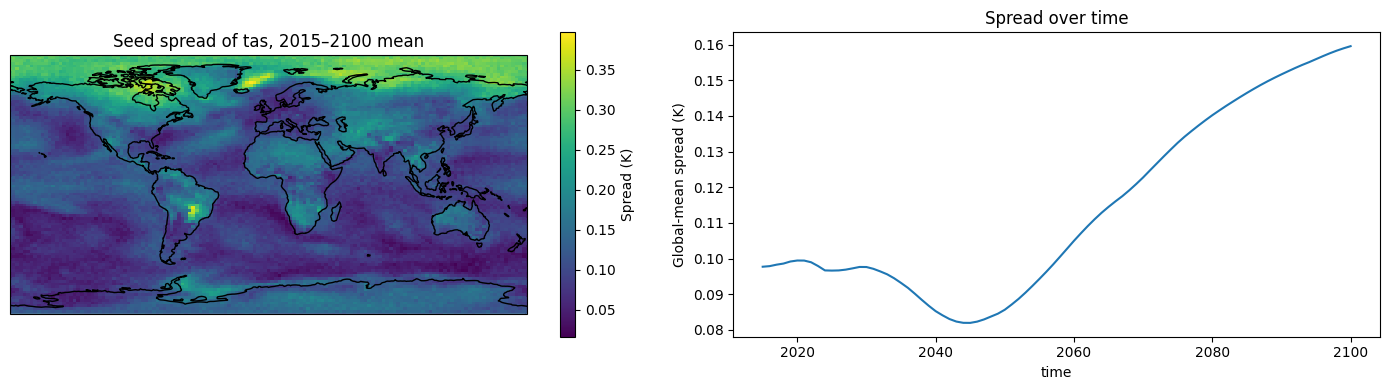

In [28]:
spread = xr_spread["tas_spread"]
weights = np.cos(np.deg2rad(spread.lat))          # weight grid cells by area
global_spread = spread.weighted(weights).mean(("lat", "lon"))

fig = plt.figure(figsize=(14, 4))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
spread.mean("time").plot(ax=ax1, transform=ccrs.PlateCarree(), cmap="viridis",
                         cbar_kwargs={"label": "Spread (K)"})
ax1.coastlines(); ax1.set_title("Seed spread of tas, 2015–2100 mean")
ax2 = fig.add_subplot(1, 2, 2)
global_spread.plot(ax=ax2)
ax2.set_ylabel("Global-mean spread (K)"); ax2.set_title("Spread over time")
plt.tight_layout()
print(f"Global-mean spread, 2015–2100: {float(global_spread.mean()):.3f} K")

# Train model

In [18]:
X_train_all.shape, Y_train_all.shape

((726, 10, 96, 144, 4), (726, 1, 96, 144))

In [20]:
hist = cnn_model.fit(X_train_all,
                     Y_train_all,
                     batch_size=16,
                     epochs=30,
                     verbose=1)

Epoch 1/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 21s 410ms/step - loss: 0.2866 - mse: 0.2866
Epoch 2/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 410ms/step - loss: 0.2834 - mse: 0.2834
Epoch 3/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 401ms/step - loss: 0.2827 - mse: 0.2827
Epoch 4/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 385ms/step - loss: 0.2820 - mse: 0.2820
Epoch 5/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 380ms/step - loss: 0.2815 - mse: 0.2815
Epoch 6/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 24s 527ms/step - loss: 0.2809 - mse: 0.2809
Epoch 7/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 22s 464ms/step - loss: 0.2803 - mse: 0.2803
Epoch 8/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 37s 808ms/step - loss: 0.2797 - mse: 0.2797
Epoch 9/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 37s 780ms/step - loss: 0.2791 - mse: 0.2791
Epoch 10/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 615ms/step - loss: 0.2785 - mse: 0.2785
Epoch 11/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 28s 594ms/step - loss: 0.2780 - mse: 0.2780
Epoch 12/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 635ms/step - loss: 0.2774 - mse: 0.2774
Epoch 13/30
4

## 6. Predicting the held-out scenario: SSP245

SSP245 was never used in training, so it tests whether the emulator can handle a new scenario. Its forcing lies between SSP126 and SSP370, which are both in the training set. The cell:

1. passes all 242 test windows (`X_test_np`) through the trained `cnn_model`, giving one 96 × 144 temperature map per year from 1859 to 2100,
2. removes the extra length-1 dimension so the result is (time, lat, lon),
3. wraps it in an xarray dataset labelled with years, latitudes and longitudes, and
4. keeps 2015–2100, the period ClimateBench evaluates.


# Make final prediction for submission

In [22]:
# Make predictions using trained model 
m_pred = cnn_model.predict(X_test_np)
# reshape to xarray 
m_pred = m_pred.reshape(m_pred.shape[0], m_pred.shape[2], m_pred.shape[3])
m_pred = xr.DataArray(m_pred, dims=['time', 'lat', 'lon'], coords=[X_test.time.data[slider-1:], X_test.latitude.data, X_test.longitude.data])
m_pred = m_pred.transpose('lat', 'lon', 'time').sel(time=slice(2015, 2101)).to_dataset(name=var_to_predict)
if ((var_to_predict == "pr90") | (var_to_predict == "pr")):
    m_pred = m_pred.assign({var_to_predict: m_pred[var_to_predict] / 86400})
m_pred

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 140ms/step


<xarray.Dataset> Size: 5MB
Dimensions:  (time: 86, lat: 96, lon: 144)
Coordinates:
  * time     (time) int64 688B 2015 2016 2017 2018 2019 ... 2097 2098 2099 2100
  * lat      (lat) float64 768B -90.0 -88.11 -86.21 -84.32 ... 86.21 88.11 90.0
  * lon      (lon) float64 1kB 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
Data variables:
    tas      (lat, lon, time) float32 5MB 1.054 1.063 1.072 ... 5.984 6.004

**Result.** Prediction took about 4 seconds (8 batches covering the 242 windows). The output is a `tas` dataset of 86 years × 96 latitudes × 144 longitudes, in kelvin of warming relative to pre-industrial.

The preview shows the first and last stored values:

| Grid cell | Years | Predicted warming |
|---|---|---|
| South Pole (first in storage order) | 2015–2017 | 1.05–1.07 K |
| North Pole (last in storage order) | 2099–2100 | 5.98–6.00 K |

These are single grid cells at different times, so they don't compare regions directly. The maps below give the full picture.

### Results: predicted temperature change in 2020, 2050 and 2100

The next cell maps the predicted warming for three years. The colour scale is centred on 0 K: red is warmer and blue is cooler than pre-industrial.

**How to read these maps**
- The maps are drawn on the model grid without coastlines. North is at the top. Longitude runs from 0° (Greenwich) at the left edge to 357.5° at the right, so the Pacific is in the middle, Africa and Europe are on the left, and the Americas are on the right.
- The scale stops at +4 K, so anything warmer shows as the same dark red.
- The blue half of the scale (−2 to 0 K) is drawn as long as the red half (0 to +4 K). As a result, a −1 K patch looks as strong as a +2 K patch.

tas


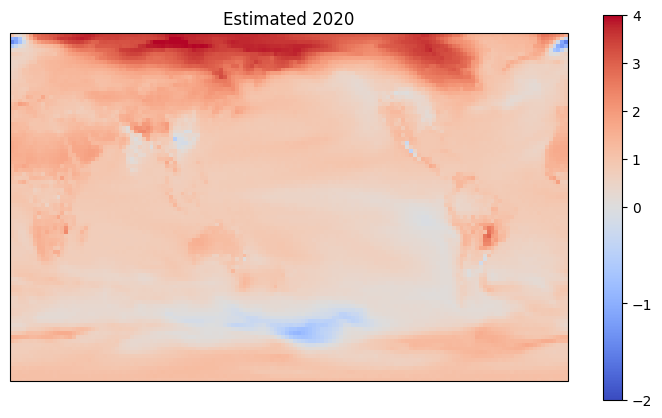

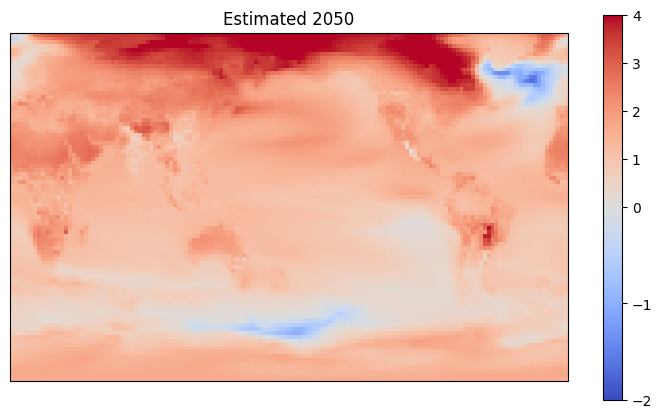

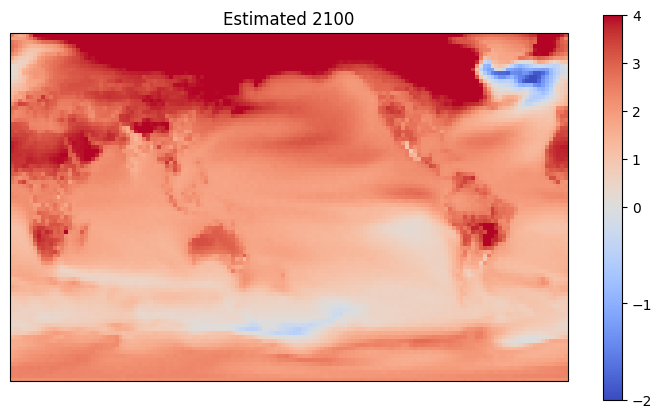

In [23]:
# Plot results 
from matplotlib import colors
divnorm = colors.TwoSlopeNorm(vmin=-2., vcenter=0., vmax=4.)

print(var_to_predict)
for yr in [2020, 2050, 2100]: 
    f, axes = plt.subplots(1, 1,
                           subplot_kw=dict(projection=ccrs.PlateCarree()),
                           figsize=(9, 5))

    ctr = axes.pcolormesh(m_pred[var_to_predict].sel(time=yr), cmap="coolwarm", norm=divnorm)
    plt.colorbar(ctr)
    axes.set_title(f"Estimated {yr}")

**What the maps show** (values read by eye from the colour scale)

- **Warming grows steadily through the century.** In 2020 most of the globe is about 0.5–1.5 K warmer than pre-industrial. By 2050 most land is 2–3 K warmer, and by 2100 much of the land is 3–4 K warmer.
- **The Arctic warms fastest (Arctic amplification).** The top of each map is the darkest red. Parts of Siberia and northern Canada already reach 3–4 K in 2020. By 2100 a wide band of high northern latitudes is past the +4 K end of the scale, and the dataset preview shows about 6 K at the North Pole.
- **Land warms more than ocean.** In every map the continents stand out as darker shapes against the oceans. By 2100 the warming is especially strong over central South America, Europe and the Middle East, southern Africa and Australia.
- **A cool patch appears in the North Atlantic.** Near Greenland, a blue patch shows up by 2050 and deepens by 2100 (roughly −1 to −2 K). It resembles the "North Atlantic warming hole" that many physics-based models project, which is often linked to a slowdown of the Atlantic overturning circulation.
- **The Southern Ocean warms slowly.** A pale band circles Antarctica in all three maps. A blue patch (about −1 K) in its Pacific sector in 2020 weakens by 2100. Physics-based models also show slow Southern Ocean warming, because cold deep water rises to the surface there.
- **Warming is weak in the south-eastern Pacific**, west of South America, throughout the century.

**Caveats**
- These are the emulator's predictions only. Comparing them with the true SSP245 simulation (`outputs_ssp245.nc`) would show whether features like the North Atlantic cool patch are real or artifacts of the emulator.
- They come from a single trained model. Section 4a showed that changing the random seed alone shifts predictions by a few tenths of a kelvin.

In [27]:
# Save test predictions as .nc 
output_name = f'outputs_ssp245_predict_{var_to_predict}.nc'
m_pred.to_netcdf(data_path + output_name, 'w')

## 7. Full pipeline: all four target variables

### Prepare the test inputs
This cell repeats the test-data preparation from section 6 so this section can run on its own. It loads the `historical` + `ssp245` inputs, normalizes them with the training statistics, and cuts them into 242 ten-year windows. It also lists the four target variables: `tas`, `diurnal_temperature_range`, `pr` and `pr90`.

# Run training and predictions for each target variable

In [25]:
vars_to_predict = ['tas', 'diurnal_temperature_range', 'pr', 'pr90']

# Open and reformat test data 
X_test = xr.open_mfdataset([data_path + 'inputs_historical.nc',
                            data_path + 'inputs_ssp245.nc']).compute()

# Normalize input data 
for var in ['CO2', 'CH4', 'SO2', 'BC']: 
    var_dims = X_test[var].dims
    X_test = X_test.assign({var: (var_dims, normalize(X_test[var].data, var, meanstd_inputs))}) 
    
X_test_np = input_for_training(X_test, skip_historical=False, len_historical=len_historical)  

### Train one model per variable and save the predictions

The inputs are the same for every variable; only the target changes. For each variable, the loop:

1. builds the training targets `Y_train_all` for that variable (the inputs `X_train_all` are rebuilt too, but they don't change),
2. clears the Keras session and builds a **fresh** CNN-LSTM, so nothing carries over from the previous variable,
3. trains it for 30 epochs with batch size 16, without printing progress (`verbose=0`),
4. predicts SSP245 and packages the result as an xarray dataset for 2015–2100,
5. converts `pr` and `pr90` back to kg m⁻² s⁻¹ (÷ 86 400) to match the original ClimateBench units, and
6. saves the prediction as a NetCDF file.

| Variable | Saved file | Units |
|---|---|---|
| `tas` | `outputs_ssp245_predict_tas.nc` | K |
| `diurnal_temperature_range` | `outputs_ssp245_predict_dtr.nc` | K |
| `pr` | `outputs_ssp245_predict_pr.nc` | kg m⁻² s⁻¹ |
| `pr90` | `outputs_ssp245_predict_pr90.nc` | kg m⁻² s⁻¹ |

In [26]:
for var_to_predict in vars_to_predict:
    
    print(var_to_predict)
    
    # Data
    X_train_all = np.concatenate([input_for_training(X_train_norm[i], skip_historical=(i<2), len_historical=len_historical) for i in range(len(simus))], axis = 0)
    Y_train_all = np.concatenate([output_for_training(Y_train[i], var_to_predict, skip_historical=(i<2), len_historical=len_historical) for i in range(len(simus))], axis=0)
    print(X_train_all.shape)
    print(Y_train_all.shape)
    
    # Model    
    keras.backend.clear_session()
    cnn_model = None
    
    cnn_model = Sequential()
    cnn_model.add(Input(shape=(slider, 96, 144, 4)))
    cnn_model.add(TimeDistributed(Conv2D(20, (3, 3), padding='same', activation='relu'), input_shape=(slider, 96, 144, 4)))
    cnn_model.add(TimeDistributed(AveragePooling2D(2)))
    cnn_model.add(TimeDistributed(GlobalAveragePooling2D()))
    cnn_model.add(LSTM(25, activation='relu'))
    cnn_model.add(Dense(1*96*144))
    cnn_model.add(Activation('linear'))
    cnn_model.add(Reshape((1, 96, 144)))
    
    cnn_model.compile(optimizer="rmsprop", loss="mse", metrics=["mse"])
    
    hist = cnn_model.fit(X_train_all,
                         Y_train_all,
                         batch_size=16,
                         epochs=30,
                         verbose=0)
    
    # Make predictions using trained model 
    m_pred = cnn_model.predict(X_test_np)
    # Reshape to xarray 
    m_pred = m_pred.reshape(m_pred.shape[0], m_pred.shape[2], m_pred.shape[3])
    m_pred = xr.DataArray(m_pred, dims=['time', 'lat', 'lon'], coords=[X_test.time.data[slider-1:], X_test.latitude.data, X_test.longitude.data])
    xr_prediction = m_pred.transpose('lat', 'lon', 'time').sel(time=slice(2015,2101)).to_dataset(name=var_to_predict)

    if var_to_predict=="pr90" or var_to_predict=="pr":
        xr_prediction = xr_prediction.assign({var_to_predict: xr_prediction[var_to_predict] / 86400})

    # Save test predictions as .nc 
    if var_to_predict == 'diurnal_temperature_range':
        xr_prediction.to_netcdf(data_path + 'outputs_ssp245_predict_dtr.nc', 'w')
    else:
        xr_prediction.to_netcdf(data_path + 'outputs_ssp245_predict_{}.nc'.format(var_to_predict), 'w')
    xr_prediction.close()


tas
(726, 10, 96, 144, 4)
(726, 1, 96, 144)


/Users/linuslee/miniforge3/lib/python3.12/site-packages/keras/src/layers/core/wrapper.py:27: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step
diurnal_temperature_range
(726, 10, 96, 144, 4)
(726, 1, 96, 144)
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step
pr
(726, 10, 96, 144, 4)
(726, 1, 96, 144)
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step
pr90
(726, 10, 96, 144, 4)
(726, 1, 96, 144)
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step


**Result.** All four models trained and saved their predictions without errors. The loop took **48 minutes** in total: 120 epochs, or about 12 minutes per variable.

- Every variable used the same 726 training samples, with inputs of shape (726, 10, 96, 144, 4) and targets of shape (726, 1, 96, 144).
- Each prediction took about a second (8 batches covering the 242 test windows).


**Things to keep in mind**
- Training ran silently and `hist` was overwritten for each variable, so no loss values were recorded. The pipeline therefore runs end to end, but this cell doesn't show how well each variable was learned.
- No random seed is set in this loop, so a re-run will produce slightly different files.
- The `tas` model here is a separate training run from the one mapped in section 6. Its saved predictions will differ from those maps by roughly the seed-to-seed spread from section 4a.

# SSP245 predictions for all four variables

This section loads the four prediction files saved by the loop above and summarizes them in one place:

1. a table of the global-mean change in 2020, 2050 and 2100,
2. the global-mean change over time for each variable,
3. maps of each variable in 2020, 2050 and 2100, and
4. where the five seed-ensemble models disagree most (if the seed-ensemble cells were run in this session).

Precipitation is shown in mm/day; the files store it in kg m⁻² s⁻¹, so it is multiplied by 86 400 here. Global means are weighted by the cosine of latitude, because grid cells near the poles cover much less area than cells near the equator.

These cells only need `data_path` and the saved `.nc` files, so they can be run on their own without retraining.

In [5]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

summary_files = {
    'tas': 'outputs_ssp245_predict_tas.nc',
    'diurnal_temperature_range': 'outputs_ssp245_predict_dtr.nc',
    'pr': 'outputs_ssp245_predict_pr.nc',
    'pr90': 'outputs_ssp245_predict_pr90.nc',
}
summary_units = {'tas': 'K', 'diurnal_temperature_range': 'K', 'pr': 'mm/day', 'pr90': 'mm/day'}
summary_labels = {'tas': 'Surface air temperature',
                  'diurnal_temperature_range': 'Diurnal temperature range',
                  'pr': 'Precipitation',
                  'pr90': 'Extreme precipitation (pr90)'}
summary_years = [2020, 2050, 2100]


def area_mean(da):
    # Area-weighted global mean
    return da.weighted(np.cos(np.deg2rad(da.lat))).mean(['lat', 'lon'])


ssp245_preds = {}
for var, fname in summary_files.items():
    with xr.open_dataset(data_path + fname) as ds:
        da = ds[var].load()
    if var in ('pr', 'pr90'):
        da = da * 86400                      # kg m-2 s-1 -> mm/day
    ssp245_preds[var] = da.transpose('time', 'lat', 'lon')
    print(f'{var:27s} {int(da.time[0])}–{int(da.time[-1])}, '
          f'{da.sizes["lat"]} × {da.sizes["lon"]} grid, {summary_units[var]}')

tas                         2015–2100, 96 × 144 grid, K
diurnal_temperature_range   2015–2100, 96 × 144 grid, K
pr                          2015–2100, 96 × 144 grid, mm/day
pr90                        2015–2100, 96 × 144 grid, mm/day


## Comparing the predictions with the true SSP245 simulation

The predictions are scored against `outputs_ssp245.nc`, the NorESM2-LM simulation of SSP245, which was never used in training. Following ClimateBench, the scores use the last 21 years (2080–2100), and the true data are averaged over ensemble members, the same way the training targets were.

- **NRMSE_s (spatial):** the area-weighted RMSE between the predicted and true 2080–2100 mean maps. It measures whether the regional pattern is right.
- **NRMSE_g (global):** the RMSE between the predicted and true yearly global means over 2080–2100. It measures whether the overall amount of change is right.
- **Total = NRMSE_s + 5 × NRMSE_g.** ClimateBench gives the global error extra weight.

Both are divided by the size of the true global-mean change, so they are unitless and comparable across variables. For example, NRMSE_s = 0.1 means the typical map error is 10% of the true change. Lower is better.

In [14]:
truth_ds = xr.open_dataset(data_path + 'outputs_ssp245.nc')
if 'member' in truth_ds.dims:
    truth_ds = truth_ds.mean('member')          # ensemble mean, like the training targets
truth_ds = truth_ds.drop_vars('quantile', errors='ignore')

def to_years(da):
    # Use plain integer years as time labels, whatever format the file uses
    t = da['time']
    years = t.values.astype(int) if np.issubdtype(t.dtype, np.number) else t.dt.year.values
    return da.assign_coords(time=years)

start, end = 2080, 2100                         # ClimateBench scores the last 21 years
rows = []
for var, pred in ssp245_preds.items():
    truth = to_years(truth_ds[var]).transpose('time', 'lat', 'lon').load()
    if var in ('pr', 'pr90'):
        truth = truth * 86400                   # kg m-2 s-1 -> mm/day, like the predictions

    # Same grid check, then copy coordinates so tiny float differences can't misalign cells
    if not (np.allclose(pred.lat, truth.lat) and np.allclose(pred.lon, truth.lon)):
        raise ValueError(f'{var}: prediction and truth are on different grids')
    pred = pred.assign_coords(lat=truth.lat, lon=truth.lon)

    t = truth.sel(time=slice(start, end))
    p = pred.sel(time=slice(start, end))
    assert t.sizes['time'] == p.sizes['time'] == end - start + 1, f'{var}: missing years'

    true_change = float(area_mean(t.mean('time')))                              # size of the true signal
    rmse_s = float(np.sqrt(area_mean((p.mean('time') - t.mean('time')) ** 2)))  # error in the mean map
    rmse_g = float(np.sqrt(((area_mean(p) - area_mean(t)) ** 2).mean('time')))  # error in the global mean
    nrmse_s, nrmse_g = rmse_s / abs(true_change), rmse_g / abs(true_change)

    rows.append({'Variable': var, 'Units': summary_units[var],
                 'True change (2080–2100)': true_change,
                 'Spatial RMSE': rmse_s, 'Global RMSE': rmse_g,
                 'NRMSE_s': nrmse_s, 'NRMSE_g': nrmse_g,
                 'Total NRMSE': nrmse_s + 5 * nrmse_g})

nrmse_table = pd.DataFrame(rows).set_index('Variable').round(3)
nrmse_table

,Units,True change (2080–2100),Spatial RMSE,Global RMSE,NRMSE_s,NRMSE_g,Total NRMSE
Variable,,,,,,,
tas,K,2.071,0.171,0.116,0.083,0.056,0.363
diurnal_temperature_range,K,-0.011,0.086,0.013,7.693,1.194,13.661
pr,mm/day,0.065,0.134,0.017,2.056,0.260,3.356
pr90,mm/day,0.155,0.387,0.051,2.501,0.331,4.158


- **Temperature is the only variable where the metric works as intended.** The true warming (2.07 K) is large and has the same sign almost everywhere, so the scores read directly: the typical local error is 8% of the warming and the global-mean error is 6%.
- **DTR's huge scores come from the denominator, not the errors.** The errors are under a tenth of a kelvin, but the true global-mean change is only −0.011 K, so dividing by it inflates them about 90 times. Greenhouse gases and declining aerosols push DTR in opposite directions, and regional increases and decreases cancel further in the global mean.
- **Precipitation is a pattern problem.** For `pr` and `pr90` the global-mean errors are fairly small (NRMSE_g 0.26 and 0.33), but the map errors are more than twice the global-mean change. Precipitation changes in both directions, wetter in some regions and drier in others, so the global mean is small while local changes, and local errors, are not.
- **Spatial errors exceed global errors for every variable**, by 1.5× for `tas` and 6–8× for the other three. Regional errors are squared before averaging, so they can't cancel; in the global mean, regions that are too high and too low partly offset each other.

In [15]:
nrmse_table = pd.DataFrame(rows).set_index('Variable').round(3)
PUBLISHED_DF = {"tas": (0.107, 0.044, 0.327), "diurnal_temperature_range": (9.917, 1.372, 16.778),
                "pr": (2.128, 0.209, 3.175), "pr90": (2.610, 0.346, 4.339)}
metrics = ['NRMSE_s', 'NRMSE_g', 'Total NRMSE']
mine = nrmse_table[metrics]
published = pd.DataFrame.from_dict(PUBLISHED_DF, orient='index', columns=metrics).loc[mine.index]

comparison = pd.concat(
    {m: pd.DataFrame({'Prediction': mine[m],
                      'Published NN': published[m],
                      'Difference': mine[m] - published[m]})
     for m in metrics},
    axis=1).round(3)


comparison.style.format('{:.3f}')

**What this shows.**
- **Reproduced.** Our run lands close to the published CNN-LSTM on every score. Its spatial score is lower for all four variables. Its Total is lower for DTR and `pr90` and higher for `tas` and `pr`, because the Total counts the global score five times. All of these differences are within the seed-to-seed variation measured in 8.3, so we treat this as a reproduction, not an improvement.
- **On `tas`, the CNN-LSTM beats every emissions-only emulator except the published CNN-LSTM itself.** It is ahead of the Gaussian process (0.478), the random forest (0.400) and the team's emissions-only pattern scaling (0.383). The published pattern-scaling row (0.320) is lower, but as the team's pattern-scaling analysis showed, it is fed the smoothed true global temperature of SSP2-4.5, so it isn't a like-for-like comparison.
- **Both CNN-LSTM runs score better on DTR than the other emulators.** Compared with pattern scaling, a plausible reason is structural. Pattern scaling applies one fixed pattern per kelvin of warming, while the CNN-LSTM combines 25 learned patterns with weights driven by the full emission history, including SO₂ and black carbon. That lets it follow aerosol-driven changes that don't scale with global temperature, which matter most for DTR. We haven't tested this directly.

### 8.3 How much of this is training randomness?

Five `tas` models, identical except for the random seed, reached almost the same training loss after 30 epochs:

| Seed | 6 | 42 | 123 | 2023 | 999 |
|---|---|---|---|---|---|
| Final training MSE (K²) | 0.290 | 0.286 | 0.286 | 0.286 | 0.285 |

**What this shows.**

- **Training loss can't tell the seeds apart, but their predictions differ.** The final losses agree within 2%, yet on SSP2-4.5 the five models differ by 0.114 K at a typical grid cell (area-weighted mean of the seed spread over 2015–2100). The training data pin the model down well; the unseen scenario doesn't.
- **The disagreement grows late in the century.** The global-mean spread is about 0.10 K until 2030, dips to about 0.08 K around 2045 and then climbs to 0.16 K by 2100. The output is a weighted sum of learned patterns, so small differences between the seeds' patterns likely grow as the weights grow with warming.
- **The seeds disagree most where the maps show their most striking features.** The spread is largest (0.3–0.4 K) over the Canadian Arctic, the seas east of Greenland and central South America, and smallest over the tropical oceans (under 0.1 K). The North Atlantic cool patch and the hotspot over central South America in the section 6 maps are therefore the least reliable parts of those maps.
- **Training randomness is a large share of the error.** Over the scored period (2080–2100) the seed spread is about 0.14–0.16 K, close to our spatial RMSE of 0.171 K. If the seed differences are independent of the error all seeds share, that shared error is only about √(0.171² − 0.15²) ≈ 0.08 K, and a five-seed average would land near 0.11 K instead of 0.17 K. This is a rough estimate, but it makes scoring the ensemble mean the cheapest next experiment.